In [1]:
import helpy
import pandas as pd
from single_analysis import Analysis

pd.set_option('display.max_rows', 10)
pd.set_option('display.max_columns', 10)

In [2]:
analysis_df = helpy.get_analysis_df(.08, 100, 3)

In [3]:
# list of models to test effectiveness of
training_range = (2007, 2020)
testing_range = (2021, 2025)

base_analysis = Analysis(analysis_df, training_range=training_range, testing_range=testing_range)

base_analysis.get_predictors()

In [4]:
base_analysis.predictors

{'Residuals': <fip_predictor.FIP_Predictor at 0x7cf05be279e0>,
 'Usage': <fip_predictor.FIP_Predictor at 0x7cf05be264b0>}

In [5]:
base_analysis.predictor_results.sort_values('R2', ascending=False)

,Feature Set,Model,MAE,RMSE,R2
1,Residuals,XGBoost,12.142887,15.334099,0.266637
2,Residuals,Random Forest,12.181163,15.345863,0.265511
0,Residuals,Elastic Net,12.286600,15.349199,0.265192
3,Usage,Random Forest,12.520173,15.702606,0.230965


In [6]:
base_analysis.get_lppm_scores()

In [7]:
base_analysis.results_df

,PlayerName,Season,FIP-,ERA-,pivFA,...,pred_Usage_rf,Residuals_rf_score,Residuals_xgb_score,Residuals_en_score,Usage_rf_score
0,Aaron Civale,2021,114.279639,90.588031,91.495320,...,104.515812,5.535865,3.448860,3.451866,5.747371
1,Aaron Civale,2023,84.753358,82.963375,91.925195,...,91.023058,-2.176861,1.956151,-1.625271,0.901850
2,Aaron Civale,2024,118.198572,110.490439,92.110243,...,104.023189,5.451050,8.708056,1.271873,3.682670
3,Aaron Civale,2025,110.313836,118.279832,92.038485,...,104.424823,2.894040,0.730972,3.841964,1.892147
4,Aaron Nola,2021,77.268658,109.811032,93.058178,...,89.282340,-0.697969,0.831741,-0.939044,0.446991
...,...,...,...,...,...,...,...,...,...,...,...
453,Zack Wheeler,2021,59.142138,65.997313,97.335892,...,78.906503,-3.563498,0.486412,-0.983777,-1.787224
454,Zack Wheeler,2022,71.175719,69.673653,96.103651,...,79.849338,-0.245444,3.066352,-3.249432,1.807728
455,Zack Wheeler,2023,70.699745,81.310410,95.962228,...,80.755894,-1.534195,2.489841,-3.299256,0.579597
456,Zack Wheeler,2024,75.354912,60.249158,95.467899,...,88.515738,-1.124333,-2.042196,-2.139335,-0.494480


<Figure size 1000x600 with 0 Axes>

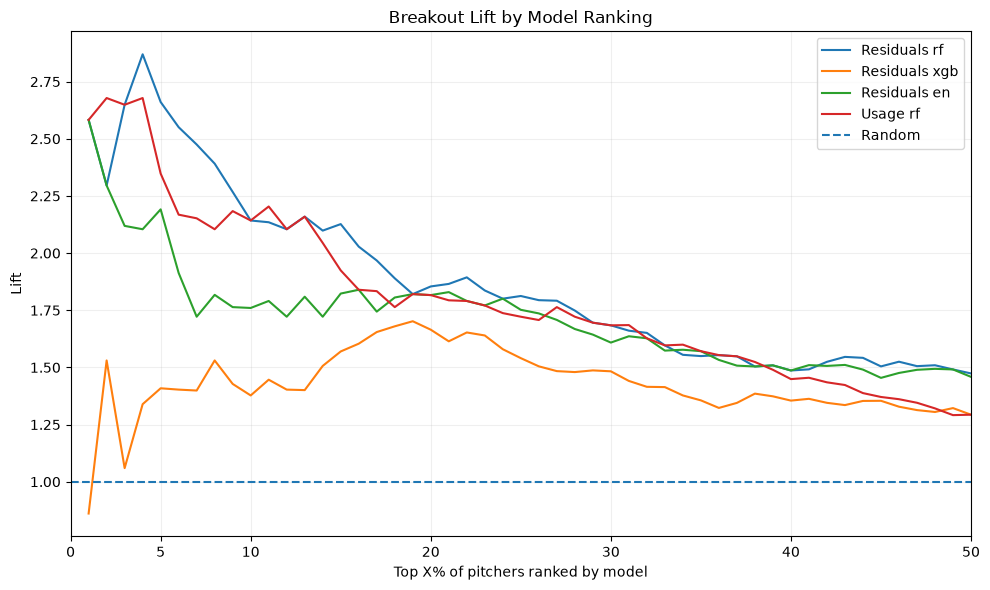

,Model,N,Breakouts,ROC-AUC,PR-AUC
0,Residuals rf,458,133,0.715928,0.527366
1,Usage rf,458,133,0.676831,0.494659
2,Residuals en,458,133,0.693279,0.473149
3,Residuals xgb,458,133,0.643678,0.396559


In [8]:
base_analysis.get_model_metrics()

In [9]:
base_analysis.results_df[['PlayerName', 'Season', 'Residuals_rf_score', 'FIP-', 'led_to_breakout']].sort_values('Residuals_rf_score', ascending=False)

,PlayerName,Season,Residuals_rf_score,FIP-,led_to_breakout
142,Gavin Williams,2025,12.532354,107.075247,True
431,Walker Buehler,2025,12.487396,136.363482,False
19,Andre Pallante,2025,12.039059,114.949947,True
114,Dustin May,2025,11.929843,115.887572,True
316,Nathan Eovaldi,2022,11.810288,108.521287,True
...,...,...,...,...,...
414,Trevor Rogers,2021,-9.319663,60.517912,False
86,Clayton Kershaw,2022,-9.536456,63.841059,False
221,Kevin Gausman,2022,-10.272365,59.721516,False
394,Spencer Strider,2022,-15.782836,47.624203,False


In [10]:
helpy.breakout_rate_suite(base_analysis.results_df, 'Residuals_rf_score', 'led_to_breakout')

Overall Breakout Rate: 29.04%
Top 5% Breakout Rate: 77.27%
Top 10% Breakout Rate: 62.22%
Top 25% Breakout Rate: 52.63%
Top 50% Breakout Rate: 42.79%


In [11]:
baseline_scores_df = helpy.create_baseline_breakout_model(analysis_df, training_range, testing_range)

In [12]:
baseline_scores_df[['score_fip', 'FIP-', 'led_to_breakout']].sort_values('score_fip', ascending=False)

,score_fip,FIP-,led_to_breakout
3165,0.443510,119.136311,False
139,0.443506,119.210677,True
215,0.443506,118.807209,False
2513,0.443500,119.299546,False
1325,0.443480,119.480978,False
...,...,...,...
2850,0.227167,62.124544,False
1139,0.226949,63.995447,False
2037,0.226942,63.121288,False
696,0.226934,63.841059,False


In [13]:
helpy.breakout_rate_suite(baseline_scores_df, 'score_fip', 'led_to_breakout')

Overall Breakout Rate: 29.04%
Top 5% Breakout Rate: 27.27%
Top 10% Breakout Rate: 42.22%
Top 25% Breakout Rate: 45.61%
Top 50% Breakout Rate: 38.86%


In [14]:
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)